# Harini Part 2 Evaluation Figures
Reproduces the shared analysis pipeline and exports two evaluation figures at 300 dpi. No nested cross-validation or threshold search is rerun. Threshold 0.16 is exploratory because it was selected on test outcomes in the shared notebook.

Run all cells in order. Download the PNG files from the Colab Files panel. References for interpretation: scikit-learn probability calibration and classification threshold documentation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             accuracy_score, roc_auc_score, brier_score_loss, f1_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); sns.set_palette('muted')
RANDOM_STATE = 42


In [2]:
DATA_URL = 'https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv'
df = pd.read_csv(DATA_URL).drop_duplicates().reset_index(drop=True)
df['disease'] = 1 - df['target']          # label correction from Part 1

CATEGORICAL = ['cp', 'restecg', 'slope', 'thal', 'ca']
CONTINUOUS  = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

X = pd.get_dummies(df.drop(columns=['target', 'disease']).astype({c: 'category' for c in CATEGORICAL}),
                   columns=CATEGORICAL, drop_first=True)
y = df['disease']

preprocessor = ColumnTransformer([('scale', StandardScaler(), CONTINUOUS)], remainder='passthrough')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(f"{df.shape[0]} patients, {X.shape[1]} features after encoding")
print(f"Disease prevalence: {y.mean():.3f} | train {X_train.shape[0]}, test {X_test.shape[0]}")

302 patients, 22 features after encoding
Disease prevalence: 0.457 | train 226, test 76


In [3]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

SEARCHES = {
    'Logistic regression': (
        Pipeline([('pre', preprocessor),
                  ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        {'clf__C': [0.01, 0.1, 1, 10, 100]}),
    'Random forest': (
        Pipeline([('pre', preprocessor),
                  ('clf', RandomForestClassifier(random_state=RANDOM_STATE))]),
        {'clf__n_estimators': [100, 300],
         'clf__max_depth': [3, 5, None],
         'clf__min_samples_leaf': [1, 3, 5]}),
}



In [4]:
# Fit the selected model for everything that follows
final = GridSearchCV(SEARCHES['Logistic regression'][0], SEARCHES['Logistic regression'][1],
                     cv=inner, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]

print(f"Selected: C = {final.best_params_['clf__C']}")
print(f"Held-out ROC-AUC: {roc_auc_score(y_test, proba):.4f}")

Selected: C = 1
Held-out ROC-AUC: 0.9261


In [5]:
brier = brier_score_loss(y_test, proba)
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=5, strategy='quantile')

print(f"Brier score: {brier:.4f}   (0 = perfect, 0.25 = uninformative)\n")
print(f"{'predicted':>10}{'observed':>10}{'gap':>8}")
for mp, fp in zip(mean_pred, frac_pos):
    print(f"{mp:>10.3f}{fp:>10.3f}{fp - mp:>8.3f}")

Brier score: 0.1105   (0 = perfect, 0.25 = uninformative)

 predicted  observed     gap
     0.037     0.000  -0.037
     0.140     0.200   0.060
     0.370     0.333  -0.036
     0.715     0.800   0.085
     0.950     1.000   0.050


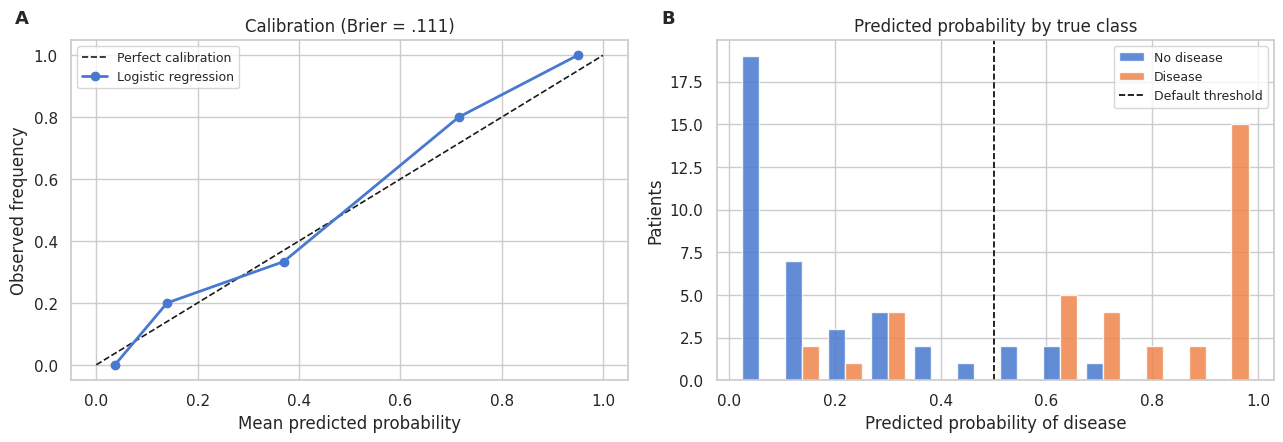

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Perfect calibration')
axes[0].plot(mean_pred, frac_pos, marker='o', linewidth=2, label='Logistic regression')
axes[0].set_xlabel('Mean predicted probability'); axes[0].set_ylabel('Observed frequency')
axes[0].set_title(f'Calibration (Brier = {brier:.3f})'.replace('0.', '.'))
axes[0].legend(fontsize=9)

axes[1].hist([proba[y_test == 0], proba[y_test == 1]], bins=12, stacked=False,
             label=['No disease', 'Disease'], alpha=.85)
axes[1].axvline(.5, color='black', linestyle='--', linewidth=1.2, label='Default threshold')
axes[1].set_xlabel('Predicted probability of disease'); axes[1].set_ylabel('Patients')
axes[1].set_title('Predicted probability by true class'); axes[1].legend(fontsize=9)

for ax, lab in zip(axes, ['A', 'B']):
    ax.text(-0.10, 1.09, lab, transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout(); plt.savefig('p2_fig1_calibration.png', dpi=300, bbox_inches='tight'); plt.show()

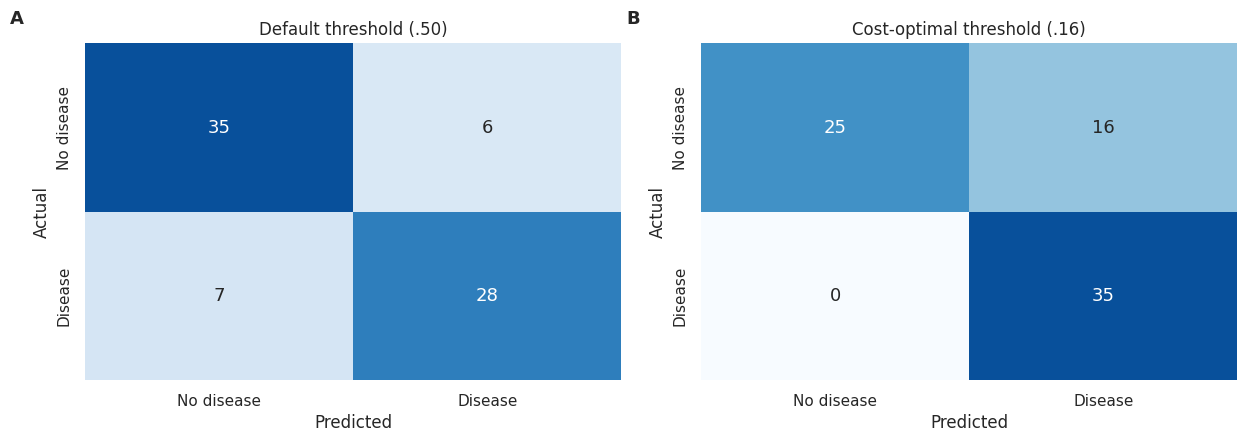

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

for ax, (t, label) in zip(axes, [(0.50, 'Default threshold (.50)'),
                                 (0.16, 'Cost-optimal threshold (.16)')]):
    cm = confusion_matrix(y_test, (proba >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No disease', 'Disease'],
                yticklabels=['No disease', 'Disease'],
                vmin=0, vmax=40, annot_kws={'size': 13})
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(label)

for ax, lab in zip(axes, ['A', 'B']):
    ax.text(-0.14, 1.10, lab, transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout(); plt.savefig('p2_fig3_confusion.png', dpi=300, bbox_inches='tight'); plt.show()

In [8]:
from google.colab import files
files.download('p2_fig1_calibration.png')
files.download('p2_fig3_confusion.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>